# Preprocessing a million-cell dataset on one GPU [`storage='disk'`]

The in-memory GPU workflow ([GPU tutorial](t_preprocess_gpu.ipynb)) first loads the whole matrix into host RAM and then into GPU memory. That stops working once the matrix is larger than either. Here we analyse the **SEA-AD middle temporal gyrus atlas** — 1,378,211 nuclei × 36,601 genes, 7.6 billion non-zero counts (≈ 91 GB as float32 + int64 indices) — on **one** GPU.

With `ov.settings.gpu_init()` and `ov.read(..., storage='disk')` the matrix stays on disk. Every step streams it to the GPU in blocks of `chunk_size` cells, so neither host nor GPU memory has to hold it. See [Choosing storage and mode](t_storage_mode.md) for how this compares with the other modes.

Requirements: `rapids-singlecell` (RAPIDS), `dask`, `anndataoom-fast>=0.1.3`.

In [1]:
import omicverse as ov
ov.plot_set()
ov.settings.gpu_init()

🔬 Starting plot initialization...
🧬 Detecting GPU devices…
🚫 PyTorch not available - GPU detection skipped

   ____            _     _    __                  
  / __ \____ ___  (_)___| |  / /__  _____________ 
 / / / / __ `__ \/ / ___/ | / / _ \/ ___/ ___/ _ \ 
/ /_/ / / / / / / / /__ | |/ /  __/ /  (__  )  __/ 
\____/_/ /_/ /_/_/\___/ |___/\___/_/  /____/\___/                                              

🔖 Version: 2.3.2   📚 Tutorials: https://omicverse.readthedocs.io/
✅ plot_set complete.



GPU mode activated


## Data

The SEA-AD release from the Allen Institute (public S3 bucket, 36 GB, gzip-compressed). `X` holds normalised values; the raw UMI counts are in `layers['UMIs']`, so we read that layer as `X`.

In [2]:
# !wget -P data https://sea-ad-single-cell-profiling.s3.amazonaws.com/MTG/RNAseq/SEAAD_MTG_RNAseq_final-nuclei.2024-02-13.h5ad
path = 'data/SEAAD_MTG_RNAseq_final-nuclei.2024-02-13.h5ad'

In [3]:
%%time
adata = ov.read(path, storage='disk', layer='UMIs', chunk_size=20000)
adata

storage='disk' (GPU) reads X, obs, var and uns; skipped: layers, obsm, obsp
CPU times: user 4.12 s, sys: 1.51 s, total: 5.63 s
Wall time: 5.7 s


AnnData object with n_obs × n_vars = 1378211 × 36601
    obs: 'sample_id', 'Neurotypical reference', 'Donor ID', 'Organism', 'Brain Region', 'Sex', 'Gender', 'Age at Death', 'Race (choice=White)', 'Race (choice=Black/ African American)', 'Race (choice=Asian)', 'Race (choice=American Indian/ Alaska Native)', 'Race (choice=Native Hawaiian or Pacific Islander)', 'Race (choice=Unknown or unreported)', 'Race (choice=Other)', 'specify other race', 'Hispanic/Latino', 'Highest level of education', 'Years of education', 'PMI', 'Fresh Brain Weight', 'Brain pH', 'Overall AD neuropathological Change', 'Thal', 'Braak', 'CERAD score', 'Overall CAA Score', 'Highest Lewy Body Disease', 'Total Microinfarcts (not observed grossly)', 'Total microinfarcts in screening sections', 'Atherosclerosis', 'Arteriolosclerosis', 'LATE', 'Cognitive Status', 'Last CASI Score', 'Interval from last CASI in months', 'Last MMSE Score', 'Interval from last MMSE in months', 'Last MOCA Score', 'Interval from last MOCA in mo

`X` is a Dask array: 69 blocks of 20,000 cells, each a CSR matrix that is read from the file and copied to the GPU only while a step needs it. Nothing has been read yet.

In [4]:
adata.X

dask.array<concatenate, shape=(1378211, 36601), dtype=float32, chunksize=(20000, 36601), chunktype=cupyx.csr_matrix>

## Quality control

One pass computes the QC metrics, a second counts cells per gene for the gene filter. Doublet detection needs the whole matrix in memory, so it is switched off here (the SEA-AD release is already doublet-filtered).

In [5]:
%%time
adata = ov.pp.qc(adata, doublets=False,
                 tresh={'mito_perc': 0.15, 'nUMIs': 500, 'detected_genes': 250})

🚀 Using RAPIDS GPU to calculate QC...

🔍 Quality Control Analysis (GPU-Accelerated):
   Dataset shape: 1,378,211 cells × 36,601 genes
   QC mode: seurat
   Doublet detection: disabled
   Auto-detected mitochondrial prefix: 'MT-'
   Mitochondrial genes: MT-

📊 Step 1: Calculating QC Metrics

   ✓ Gene Family Detection:
   ┌──────────────────────────────┬────────────────────┬────────────────────┐
   │ Gene Family                  │ Genes Found        │ Detection Method   │
   ├──────────────────────────────┼────────────────────┼────────────────────┤
   │ Mitochondrial                │ 13                 │ Auto (MT-)         │
   ├──────────────────────────────┼────────────────────┼────────────────────┤
   │ Ribosomal                    │ 103                │ Auto (RPS/RPL)     │
   ├──────────────────────────────┼────────────────────┼────────────────────┤
   │ Hemoglobin                   │ 12                 │ Auto (regex)       │
   └──────────────────────────────┴────────────────────┴


   ✓ QC Metrics Summary:
   ┌─────────────────────────┬────────────────────┬─────────────────────────┐
   │ Metric                  │ Mean               │ Range (Min - Max)       │
   ├─────────────────────────┼────────────────────┼─────────────────────────┤
   │ nUMIs                   │ 25835              │ 1221 - 511016           │
   ├─────────────────────────┼────────────────────┼─────────────────────────┤
   │ Detected Genes          │ 5530               │ 1001 - 15607            │
   ├─────────────────────────┼────────────────────┼─────────────────────────┤
   │ Mitochondrial %         │ 0.4%               │ 0.0% - 5.0%             │
   ├─────────────────────────┼────────────────────┼─────────────────────────┤
   │ Ribosomal %             │ 0.4%               │ 0.0% - 18.5%            │
   ├─────────────────────────┼────────────────────┼─────────────────────────┤
   │ Hemoglobin %            │ 0.0%               │ 0.0% - 17.8%            │
   └─────────────────────────┴────────

   ✓ Combined QC filters: 0 cells removed (0.0%)

🎯 Step 3: Final Filtering
   Parameters: min_genes=200, min_cells=3
   Ratios: max_genes_ratio=1, max_cells_ratio=1


   ✓ Final filtering: 0 cells, 754 genes removed

✅ GPU Quality Control Analysis Completed!

📈 Final Summary:
   📊 Original: 1,378,211 cells × 36,601 genes
   ✓ Final: 1,378,211 cells × 35,847 genes
   📉 Total removed: 0 cells (0.0%)
   📉 Total removed: 754 genes (2.1%)
   💯 Quality: 100.0% retention (Excellent retention rate)

────────────────────────────────────────────────────────────

╭─ SUMMARY: qc ──────────────────────────────────────────────────────╮
│  Duration: 161.2808s                                               │
│  Shape:    1,378,211 x 36,601 (Unchanged)                          │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● OBS    │ ✚ cell_complexity (float)                              │
│           │ ✚ detected_genes (float)                               │
│           │ ✚ hb_perc (float)         

## Normalisation and highly variable genes

`shiftlog|pearson`: size normalisation and log1p are applied lazily to each block; Pearson-residual HVGs are computed in one pass, which also collects the per-gene statistics `ov.pp.scale` needs.

In [6]:
%%time
adata = ov.pp.preprocess(adata, mode='shiftlog|pearson', n_HVGs=2000, target_sum=50e4)

🔍 [2026-11-09 17:56:36] Running preprocessing in 'gpu' mode...
Begin robust gene identification


✅ Robust gene identification completed successfully.
Begin size normalization: shiftlog and HVGs selection pearson


    Time to analyze data (dask): 64.47 seconds.
✅ Preprocessing completed successfully.
    Added:
        'highly_variable_features', boolean vector (adata.var)
        'means', float vector (adata.var)
        'variances', float vector (adata.var)
        'residual_variances', float vector (adata.var)
        'counts', raw counts layer (adata.layers)
    End of size normalization: shiftlog and HVGs selection pearson

╭─ SUMMARY: preprocess ──────────────────────────────────────────────╮
│  Duration: 76.7797s                                                │
│  Shape:    1,378,211 x 35,847 -> 1,378,211 x 31,374                │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● VAR    │ ✚ highly_variable (bool)                               │
│           │ ✚ highly_variable_features (bool)                      │
│        

In [7]:
%%time
ov.pp.scale(adata)
ov.pp.pca(adata, layer='scaled', n_pcs=50)


╭─ SUMMARY: scale ───────────────────────────────────────────────────╮
│  Duration: 0.0034s                                                 │
│  Shape:    1,378,211 x 31,374 (Unchanged)                          │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● LAYERS │ ✚ scaled (Array)                                       │
│                                                                    │
╰────────────────────────────────────────────────────────────────────╯



╭─ SUMMARY: pca ─────────────────────────────────────────────────────╮
│  Duration: 88.111s                                                 │
│  Shape:    1,378,211 x 31,374 (Unchanged)                          │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● UNS    │ ✚ pca                                                  │
│           │ └─ params: {'zero_center': True, 'mask_var': 'highly_varia...│
│           │ ✚ scaled|original|cum_sum_eigenvalues                  │
│           │ ✚ scaled|original|pca_var_ratios                       │
│                                                                    │
│  ● OBSM   │ ✚ X_pca (array, 1378211x50)                            │
│           │ ✚ scaled|original|X_pca (array, 1378211x50)            │
│                                                                    │

PCA reads the HVG columns of the scaled blocks once (kept on the GPU, 1.38M × 2000 floats ≈ 11 GB) for the covariance and the projection. Everything after PCA works on the 50-dimensional embedding exactly as in the in-memory GPU mode.

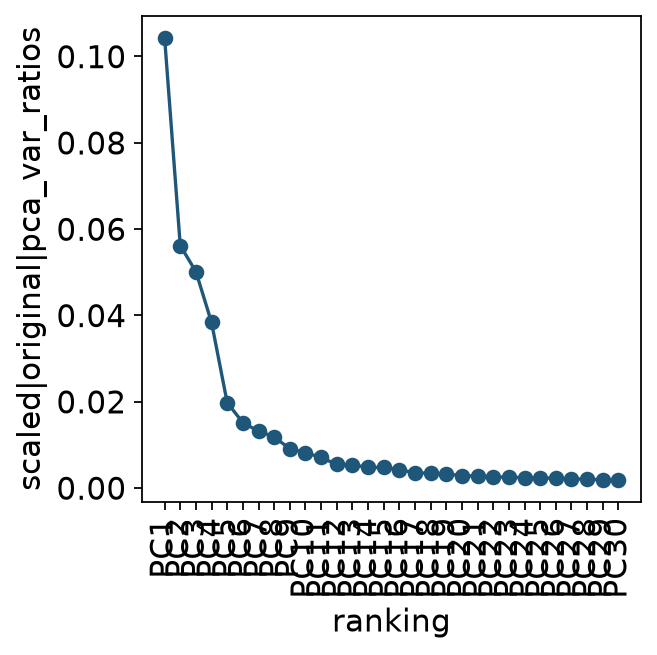

In [8]:
ov.pl.plot_pca_variance_ratio(adata)

## Neighbours, clustering and UMAP

In [9]:
%%time
ov.pp.neighbors(adata, n_neighbors=15, n_pcs=50, use_rep='scaled|original|X_pca')
ov.pp.leiden(adata, resolution=1.0)
ov.pp.umap(adata)

🚀 Using RAPIDS GPU to calculate neighbors...



╭─ SUMMARY: neighbors ───────────────────────────────────────────────╮
│  Duration: 19.8009s                                                │
│  Shape:    1,378,211 x 31,374 (Unchanged)                          │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● OBSP   │ ✚ connectivities (sparse matrix, 1378211x1378211)      │
│           │ ✚ distances (sparse matrix, 1378211x1378211)           │
│                                                                    │
╰────────────────────────────────────────────────────────────────────╯
🚀 Using RAPIDS GPU to calculate Leiden...



╭─ SUMMARY: leiden ──────────────────────────────────────────────────╮
│  Duration: 2.9152s                                                 │
│  Shape:    1,378,211 x 31,374 (Unchanged)                          │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● OBS    │ ✚ leiden (category)                                    │
│                                                                    │
│  ● UNS    │ ✚ leiden                                               │
│           │ └─ params: {'resolution': 1.0, 'random_state': 0, 'n_itera...│
│                                                                    │
╰────────────────────────────────────────────────────────────────────╯
🔍 [2026-11-09 17:59:44] Running UMAP in 'gpu' mode...
🚀 Using RAPIDS GPU UMAP...


✅ UMAP completed successfully.

╭─ SUMMARY: umap ────────────────────────────────────────────────────╮
│  Duration: 0.5143s                                                 │
│  Shape:    1,378,211 x 31,374 (Unchanged)                          │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● OBSM   │ ✚ X_umap (array, 1378211x2)                            │
│                                                                    │
╰────────────────────────────────────────────────────────────────────╯
CPU times: user 13.3 s, sys: 9.89 s, total: 23.1 s
Wall time: 23.2 s


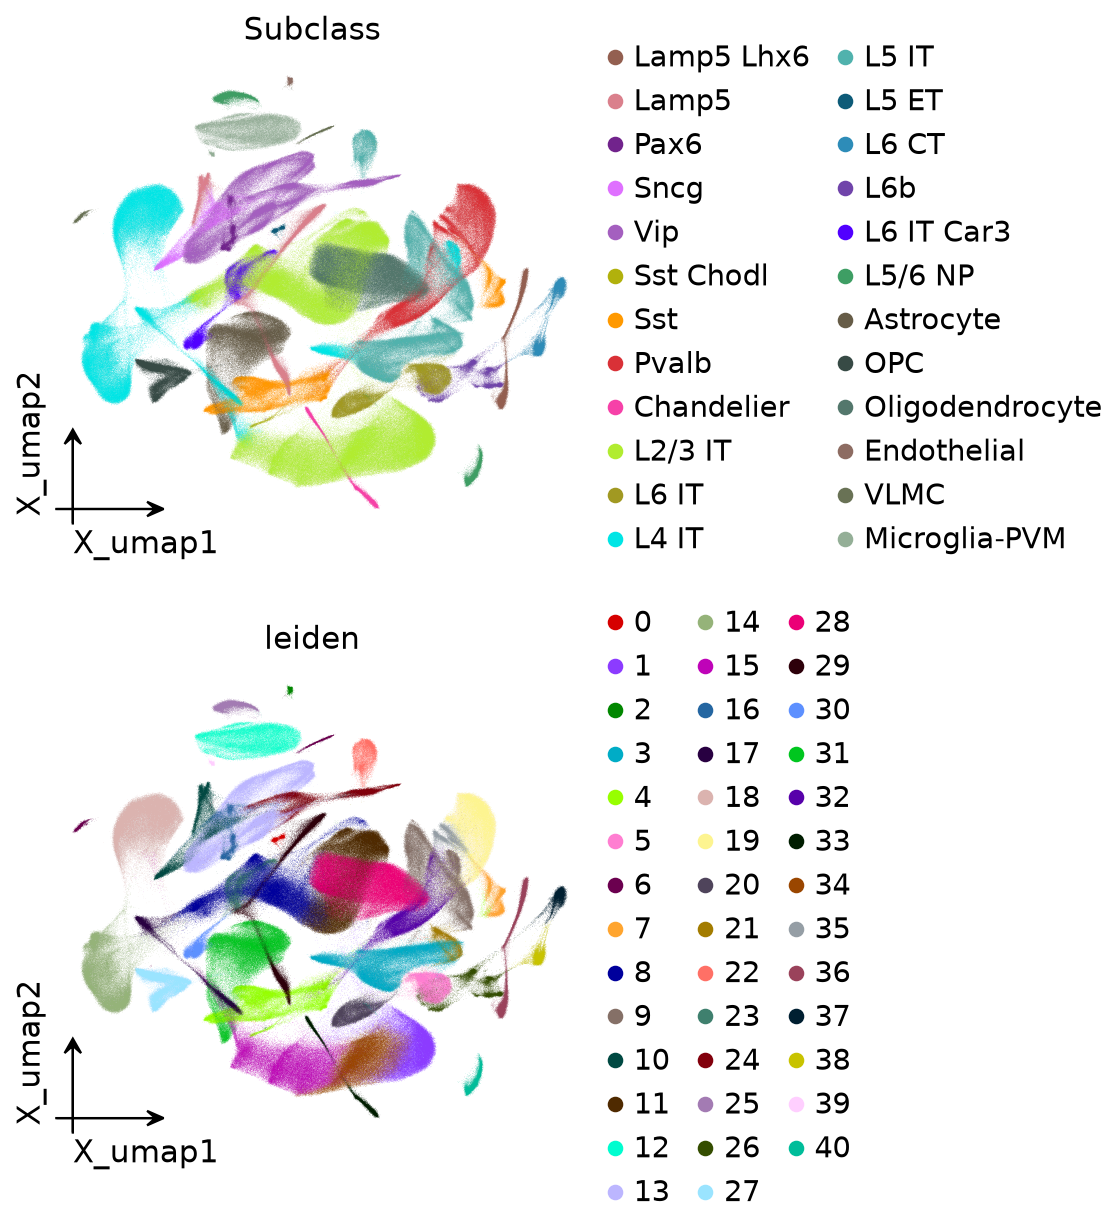

In [10]:
ov.pl.embedding(adata, basis='X_umap', color=['Subclass', 'leiden'],
                frameon='small', wspace=0.55)

## Marker genes

COSG streams the per-group sums of the normalised blocks (one more pass).

In [11]:
%%time
ov.single.find_markers(adata, groupby='Subclass', method='cosg', n_genes=5)

🔍 Finding marker genes | method: cosg | groupby: Subclass | n_groups: 24 | n_genes: 5


**finished identifying marker genes by COSG**


✅ Done | 24 groups × 5 genes | stored in adata.uns['rank_genes_groups']
CPU times: user 2min 29s, sys: 1min 52s, total: 4min 22s
Wall time: 1min 7s


In [12]:
ov.single.get_markers(adata, n_genes=3)

         group  rank    names    scores  logfoldchanges  pct_group  pct_rest
0    Astrocyte     1   PRDM16  0.854253       10.377892   0.909797  0.030894
1    Astrocyte     2   ACSBG1  0.824063       10.004189   0.892100  0.031507
2    Astrocyte     3   ETNPPL  0.819619       10.144633   0.788384  0.015229
3   Chandelier     1  COL15A1  0.398266        8.421832   0.697840  0.015499
4   Chandelier     2      NOG  0.287629        6.768747   0.252471  0.004248
..         ...   ...      ...       ...             ...        ...       ...
67        VLMC     2    TBX18  0.681998       12.276060   0.646719  0.001604
68        VLMC     3     ZIC1  0.611649       12.499931   0.883087  0.007318
69         Vip     1    CALB2  0.678592        8.046922   0.776987  0.034521
70         Vip     2      VIP  0.622467        7.762294   0.473793  0.009856
71         Vip     3   CHRNA2  0.617727        7.729186   0.450906  0.006968

[72 rows x 7 columns]

## Summary

The whole workflow read the 1.38M-cell matrix five times (QC, gene filter, HVG + scaling statistics, PCA, markers) and never held it in memory. Here, reading the gzip-compressed release, the steps took about 7.5 min on one H100. With an uncompressed copy of the file in the page cache the same steps took 55 s with 5 GB of host memory (brisc: 93 s / 114 GB on 32 CPU cores; Scanpy, as reported by the brisc authors: 1.4 h / 256 GB). Reading the compressed file is bound by decompression; write an uncompressed copy once if you will analyse it repeatedly.

What is not available on a Dask `X`: doublet detection, `pearson` normalisation and `seurat` HVGs in `preprocess`, `no_cc`, and marker methods other than COSG — each raises a clear error.